In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical

np.random.seed(42)
tf.random.set_seed(42)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

iris = load_iris()

X = iris.data
y = iris.target

print("Dataset loaded successfully!")
print("Number of rows:", X.shape[0])
print("Number of features:", X.shape[1])
print("Flower classes:", iris.target_names)


Dataset loaded successfully!
Number of rows: 150
Number of features: 4
Flower classes: ['setosa' 'versicolor' 'virginica']


In [3]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))



Training samples: 105
Testing samples: 45


In [4]:

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

y_train_cat = to_categorical(y_train, num_classes=3)
y_test_cat = to_categorical(y_test, num_classes=3)

print("Data preprocessing completed!")


Data preprocessing completed!


In [5]:

def create_model(neurons, extra_layers=False):
    model = Sequential()

    model.add(Dense(neurons, activation="relu", input_shape=(4,)))

    if extra_layers:
        model.add(Dense(neurons, activation="relu"))
        model.add(Dense(neurons, activation="relu"))

    model.add(Dense(3, activation="softmax"))

    model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


model1 = create_model(2)
model2 = create_model(16)
model3 = create_model(128, extra_layers=True)

print("All three models created successfully!")


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


All three models created successfully!


In [6]:

models = {
    "Simple Model": model1,
    "Moderate Model": model2,
    "Complex Model": model3
}

results = []
histories = {}

for name, model in models.items():
    print("\nTraining", name)

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=20,
        restore_best_weights=True
    )

    history = model.fit(
        X_train, y_train_cat,
        epochs=300,
        batch_size=8,
        validation_split=0.20,
        callbacks=[early_stop],
        verbose=0
    )

    histories[name] = history

    train_loss, train_acc = model.evaluate(
        X_train, y_train_cat, verbose=0
    )

    test_loss, test_acc = model.evaluate(
        X_test, y_test_cat, verbose=0
    )

    results.append({
        "Model": name,
        "Training Accuracy": round(train_acc, 4),
        "Testing Accuracy": round(test_acc, 4),
        "Training Loss": round(train_loss, 4),
        "Testing Loss": round(test_loss, 4)
    })

    print("Training Accuracy:", round(train_acc, 4))
    print("Testing Accuracy:", round(test_acc, 4))

print("\nTraining completed!")



Training Simple Model
Training Accuracy: 0.981
Testing Accuracy: 0.9778

Training Moderate Model
Training Accuracy: 0.9905
Testing Accuracy: 0.9111

Training Complex Model
Training Accuracy: 1.0
Testing Accuracy: 0.9111

Training completed!


In [7]:

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))


         Model  Training Accuracy  Testing Accuracy  Training Loss  Testing Loss
  Simple Model             0.9810            0.9778         0.1507        0.1902
Moderate Model             0.9905            0.9111         0.0397        0.1293
 Complex Model             1.0000            0.9111         0.0000        0.6667


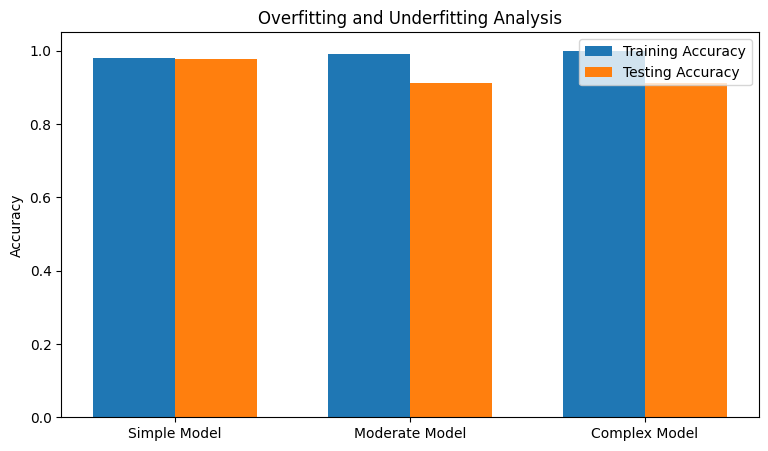

In [8]:

x = np.arange(len(results_df))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    results_df["Training Accuracy"],
    width,
    label="Training Accuracy"
)

plt.bar(
    x + width / 2,
    results_df["Testing Accuracy"],
    width,
    label="Testing Accuracy"
)

plt.xticks(x, results_df["Model"])
plt.ylabel("Accuracy")
plt.title("Overfitting and Underfitting Analysis")
plt.ylim(0, 1.05)
plt.legend()
plt.show()


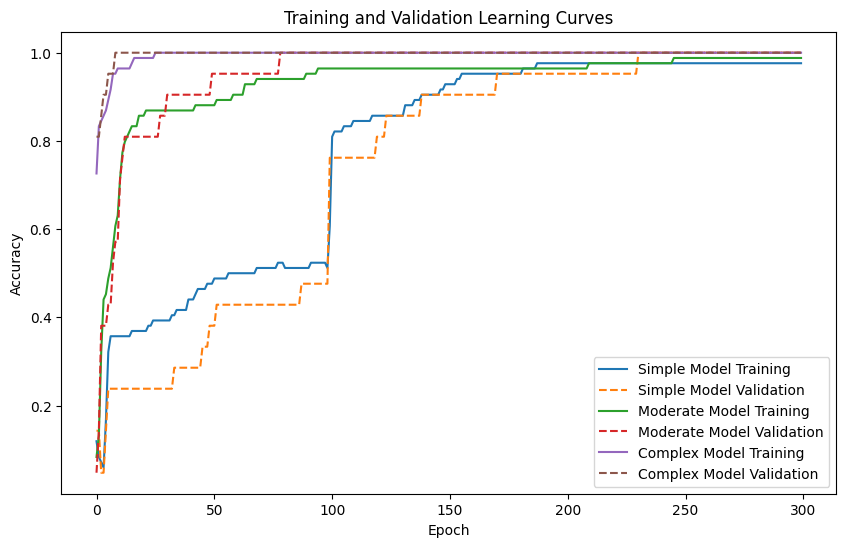

In [9]:

plt.figure(figsize=(10, 6))

for name, history in histories.items():
    plt.plot(
        history.history["accuracy"],
        label=name + " Training"
    )
    plt.plot(
        history.history["val_accuracy"],
        linestyle="--",
        label=name + " Validation"
    )

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Learning Curves")
plt.legend()
plt.show()


In [10]:

y_pred = np.argmax(
    model2.predict(X_test, verbose=0),
    axis=1
)

print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45

